In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

In [2]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

In [3]:
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory="dataset",
    batch_size=64,
    validation_split=0.3,
    seed=seed,
    output_sequence_length=16000,
    subset="both"
)

Found 6505 files belonging to 4 classes.
Using 4554 files for training.
Using 1951 files for validation.


In [4]:
label = np.array(train_ds.class_names)
print(label)

['follow' 'learn' 'tree' 'visual']


In [5]:
def squeeze(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    return audio, label

def get_spectrogram(waveform):
    spectrogram = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    spectrogram = tf.abs(spectrogram)
    spectrogram = spectrogram[..., tf.newaxis]
    return spectrogram

def make_spectrogram_ds(ds):
    return ds.map(
        map_func=lambda audio, label: (get_spectrogram(audio), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

In [6]:
# Squeeze audio
train_ds = train_ds.map(squeeze, tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, tf.data.AUTOTUNE)

# Split data to 15% test and 15% validation
test_ds = val_ds.shard(num_shards=2, index=0)
val_ds = val_ds.shard(num_shards=2, index=1)

In [7]:
# Convert waveform to spectrogram
train_spectrogram_ds = make_spectrogram_ds(train_ds)
val_spectrogram_ds = make_spectrogram_ds(val_ds)
test_spectrogram_ds = make_spectrogram_ds(test_ds)

In [8]:
# Create metadata for model (input_shape, num_label)
for example_spectrogram, example_spectrogram_label in train_spectrogram_ds.take(1):
    break

input_shape = example_spectrogram.shape[1:]
num_label=len(label)

In [9]:
# Create normalization layer
norm_layer = layers.Normalization()
norm_layer.adapt(
    data=train_spectrogram_ds.map(
        map_func=lambda spec, label: spec
    )
)

In [ ]:
# Create model
model = models.Sequential(
    [
        layers.Input(shape=input_shape),
        layers.Resizing(32, 32),
        norm_layer,
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv1D(128, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Dropout(0.5),
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_label)
    ]
)

In [11]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 32, 32, 1)         0         
                                                                 
 normalization (Normalizatio  (None, 32, 32, 1)        3         
 n)                                                              
                                                                 
 conv2d (Conv2D)             (None, 30, 30, 64)        640       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 15, 15, 64)       0         
 )                                                               
                                                                 
 conv1d (Conv1D)             (None, 15, 13, 128)       24704     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 7, 6, 128)        0

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [13]:
history = model.fit(
    train_spectrogram_ds,
    validation_data=val_spectrogram_ds,
    epochs=8,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2)
)

Epoch 1/8
72/72 [==============================] - 4s 48ms/step - loss: 0.8474 - accuracy: 0.6700 - val_loss: 0.5477 - val_accuracy: 0.7823
Epoch 2/8
72/72 [==============================] - 3s 36ms/step - loss: 0.5315 - accuracy: 0.8116 - val_loss: 0.3878 - val_accuracy: 0.8646
Epoch 3/8
72/72 [==============================] - 3s 36ms/step - loss: 0.4182 - accuracy: 0.8551 - val_loss: 0.3167 - val_accuracy: 0.8927
Epoch 4/8
72/72 [==============================] - 3s 37ms/step - loss: 0.3375 - accuracy: 0.8843 - val_loss: 0.2554 - val_accuracy: 0.9125
Epoch 5/8
72/72 [==============================] - 3s 36ms/step - loss: 0.2934 - accuracy: 0.8994 - val_loss: 0.2455 - val_accuracy: 0.9167
Epoch 6/8
72/72 [==============================] - 3s 37ms/step - loss: 0.2659 - accuracy: 0.9071 - val_loss: 0.1970 - val_accuracy: 0.9281
Epoch 7/8
72/72 [==============================] - 3s 37ms/step - loss: 0.2284 - accuracy: 0.9234 - val_loss: 0.1799 - val_accuracy: 0.9344
Epoch 8/8
72/72 [===

In [14]:
# Testing
for i, (spectrogram_batch, label_batch) in enumerate(test_spectrogram_ds):
    prediction = model.predict(spectrogram_batch)
    
    for j in range(len(label_batch)):
        true_index = label_batch[j].numpy()
        predicted_index = np.argmax(prediction[j])
        
        print(
            f"Batch: {i}, Data: {j} - Original Label: {label[true_index]} | Predicted Label: {label[predicted_index]}"
        )

2/2 [==============================] - 0s 6ms/step
Batch: 0, Data: 0 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 1 - Original Label: learn | Predicted Label: learn
Batch: 0, Data: 2 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 3 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 4 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 5 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 6 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 7 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 8 - Original Label: follow | Predicted Label: follow
Batch: 0, Data: 9 - Original Label: learn | Predicted Label: learn
Batch: 0, Data: 10 - Original Label: visual | Predicted Label: visual
Batch: 0, Data: 11 - Original Label: learn | Predicted Label: tree
Batch: 0, Data: 12 - Original Label: tree | Predicted Label: tree
Batch: 0, Data: 13 - Original Label: follow | Predicted Label: follow
Ba

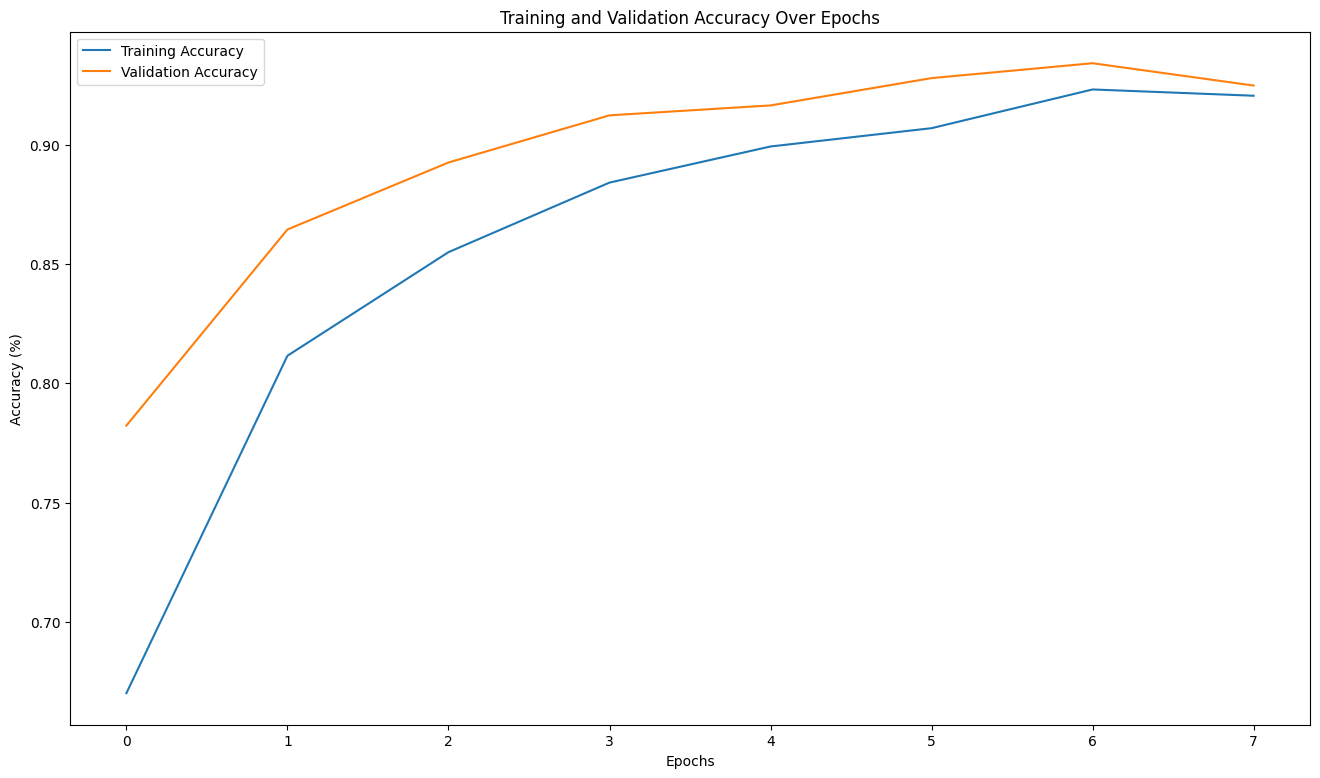

In [15]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch_range = range(len(acc))
plt.figure(figsize=(16, 9))
plt.plot(epoch_range, acc, label='Training Accuracy')
plt.plot(epoch_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()